    In this course project I am going to solve Denoising problem. In order to make my project a little closer to real world I would specify problem next way: Remove noise from weather issues (rain, snow, mist) from images that represent car licence plates.
    For this work I have chosen the dataset 'Synthetic-Ukrainian-LP-dataset-10k' (can download at https://zenodo.org/records/13342103) that contains 8000 images for training, 1000 images for validation and 1000 images for test together with corresponding annotations (annotations are not used in this project). All images have dimensions 193x72x3 pixels.
    The process pipeline:
    1) perform neccessary imports
    2) create support functions (image preprocess, add noise, display batches of images)
    3) download dataset
    4) build model CNN
    5) train model
    6) verify results

In [1]:
#step 1. Perform neccessary imports
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import keras
from keras import layers, regularizers
from keras.layers import Activation, BatchNormalization, Concatenate, Conv2D, Conv2DTranspose, Input, Rescaling, Dense, MaxPooling2D, Resizing
from keras.datasets import mnist
from keras.models import Model

# Set the seeds for reproducibility
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print("GPU memory growth enabled")
else:
    print("No GPU detected")

GPU memory growth enabled


In [4]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpus)
print("Number of GPUs:", len(gpus))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Number of GPUs: 1


In [5]:
#step 2. Create support functions

#The goal of preprocess function - reshape image to suitable form
def preprocess(array):
    array = array.astype("float32") / 255.0
    array = cv2.resize(array, (192, 72))
    return array

#The goal of noise function - add random noise to initial cleen image
def noise(array):
    noise_factor = 0.4
    noisy_array = array + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=array.shape)
    return np.clip(noisy_array, 0.0, 1.0)

#display images from 2 arrays provided by data generator (original an processed image)
def display(data_generator, batch_size):
    for array1, array2 in data_generator:
        n = min(4, len(array1))
        indices = np.random.choice(len(array1), size=n, replace=False)

        images1 = array1[indices]
        images2 = array2[indices]

        plt.figure(figsize=(16, 6))

        for i, (image1, image2) in enumerate(zip(images1, images2)):
            ax = plt.subplot(2, n, i + 1)
            plt.imshow(image1)
            ax.axis('off')

            ax = plt.subplot(2, n, i + 1 + n)
            plt.imshow(image2)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

        break

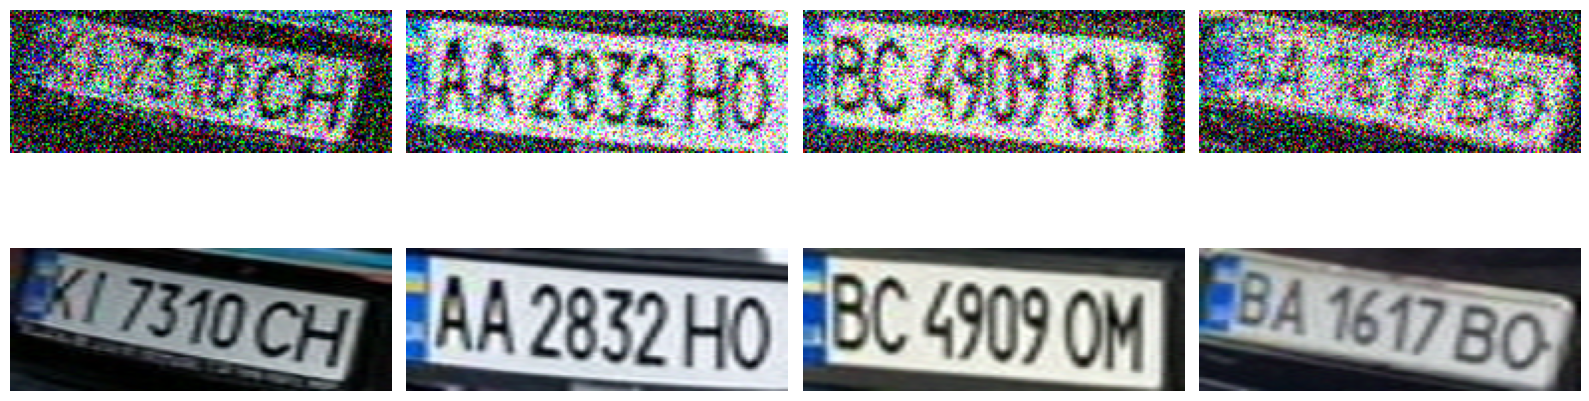

In [20]:
#step 3. Load dataset
import glob
import random

#load data from disk in bathces. create two arrays: initial images and corresponding noisy images
def load_data(images_path, batch_size, training=True):
    img_files = glob.glob(os.path.join(images_path, '*.png'))
    while True:
      if training:
        random.shuffle(img_files)
      #print(len(img_files))
      for i in range(0, len(img_files), batch_size):
        batch_files = img_files[i:i + batch_size]
        images = []
        noisy_images = []

        for img_path in batch_files:
          image = cv2.imread(img_path)
          if image is None:
            raise ValueError(f"Cannot read image: {img_path}")
          image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
          image = preprocess(image)
          noisy_image = noise(image)
          images.append(image)
          noisy_images.append(noisy_image)
        yield (np.asarray(noisy_images, dtype=np.float32), np.asarray(images, dtype=np.float32))

TRAIN_IMG_PATH = './data/train/images'
VALIDATION_IMG_PATH = './data/valid/images'

BATCH_SIZE = 16

#create data generators for both train and validation sets with 16 images in every batch
train_generator = load_data(TRAIN_IMG_PATH, BATCH_SIZE, training=True)
validation_generator = load_data(VALIDATION_IMG_PATH, BATCH_SIZE, training=False)

display(train_generator, BATCH_SIZE)

In [21]:
#check received batches dimensions
train_batch = next(train_generator)
validation_batch = next(validation_generator)

print("Training:")
print("Input:", train_batch[0].shape)
print("Target:", train_batch[1].shape)

print("\nValidation:")
print("Input:", validation_batch[0].shape)
print("Target:", validation_batch[1].shape)

Training:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)

Validation:
Input: (16, 72, 192, 3)
Target: (16, 72, 192, 3)


step 4. Build CNN model. Here I use the model from reference link.
I have changed the loss_function to 'mse' (next iterations - ssim and mse+ssim) - because
I think that the denosing problem means that the output result should be as close to original as possible
I also used 'mae' for the metrics for the same reason.
For the next iterations I will implement simplified U-net.

In [22]:
inputs = layers.Input(shape=(72, 192, 3))

# Encoder
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)

# Decoder
x = layers.Conv2DTranspose(32, (4, 4), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (4, 4), strides=2, activation="relu", padding="same")(x)
#Try layers.UpSampling2D((2, 2)) #This must separate spatial enlargement from feature extraction
outputs = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

autoencoder = Model(inputs, outputs)
#Accuracy is not a useful metric for continuous-valued image reconstruction. For example, predicting a pixel value of 0.51 instead of 0.50 is a small error, but accuracy does not meaningfully describe that error
#Try next use mse+ssim
autoencoder.compile(optimizer='adam', loss='mse', metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
autoencoder.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 72, 192, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 72, 192, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 36, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 36, 96, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 18, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 36, 96, 32)     │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 72, 192, 32)    │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 72, 192, 3)     │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,843 (171.26 KB)

 Trainable params: 43,843 (171.26 KB)

 Non-trainable params: 0 (0.00 B)

step 5. Train model
Here I use callbacks to save best model weights and earlystop to fight overfitting

In [24]:
import math
train_size = len(glob.glob(os.path.join(TRAIN_IMG_PATH, '*.png')))

validation_size = len(glob.glob(os.path.join(VALIDATION_IMG_PATH, '*.png')))

EPOCHS = 25
STEPS_PER_EPOCH = math.ceil(train_size / BATCH_SIZE)
VALIDATION_STEPS = math.ceil(validation_size / BATCH_SIZE)
print("STEPS_PER_EPOCH: ", STEPS_PER_EPOCH)
print("VALIDATION_STEPS: ", VALIDATION_STEPS)

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
earlyStop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience = 7, restore_best_weights=True, verbose=1)

history = autoencoder.fit(train_generator, steps_per_epoch=STEPS_PER_EPOCH, epochs=EPOCHS,
                          validation_data=validation_generator, validation_steps=VALIDATION_STEPS,
                          callbacks=[checkpoint, earlyStop], verbose=2)

STEPS_PER_EPOCH:  500
VALIDATION_STEPS:  63
Epoch 1/25

Epoch 1: val_loss improved from None to 0.00503, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
500/500 - 66s - 132ms/step - loss: 0.0050 - mae: 0.0551 - val_loss: 0.0050 - val_mae: 0.0552
Epoch 2/25

Epoch 2: val_loss improved from 0.00503 to 0.00432, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
500/500 - 65s - 131ms/step - loss: 0.0045 - mae: 0.0522 - val_loss: 0.0043 - val_mae: 0.0509
Epoch 3/25

Epoch 3: val_loss improved from 0.00432 to 0.00409, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
500/500 - 64s - 129ms/step - loss: 0.0042 - mae: 0.0504 - val_loss: 0.0041 - val_mae: 0.0494
Epoch 4/25

Epoch 4: val_loss improved from 0.00409 to 0.00394, saving model to best_model.keras

Epoch 4: finished saving model to best_model.keras
500/500 - 66s - 132ms/step - loss: 0.0040 - mae: 0.0492 - val_loss: 0.0039 - val_mae

Here I want to see the training process. I can make conclusion that my network does not suffer overfitting. But also it can be good idea to increase Epochs count.

Train mae      0.042537130415439606
Validation mae 0.04389823600649834


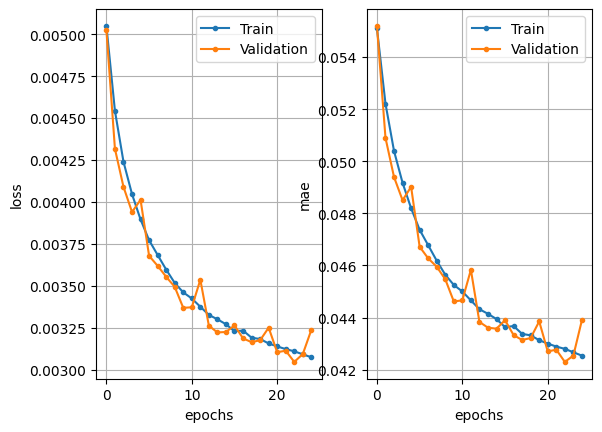

In [25]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['mae'], '.-',
                               epochs, h['val_mae'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('mae')
    plt.legend(['Train', 'Validation'])

    print('Train mae     ', h['mae'][-1])
    print('Validation mae', h['val_mae'][-1])

plot_history(history)

step 6. Verify results
The given results concerning random noise are quite promising. The denoising worked pretty good.
However the predictions appear a little blured which can be caused by too simple model and 'mse' loss function.
This is why it is neccessary to keep going transformations.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Noisy images: (16, 72, 192, 3)
Predictions: (16, 72, 192, 3)
Clean images: (16, 72, 192, 3)


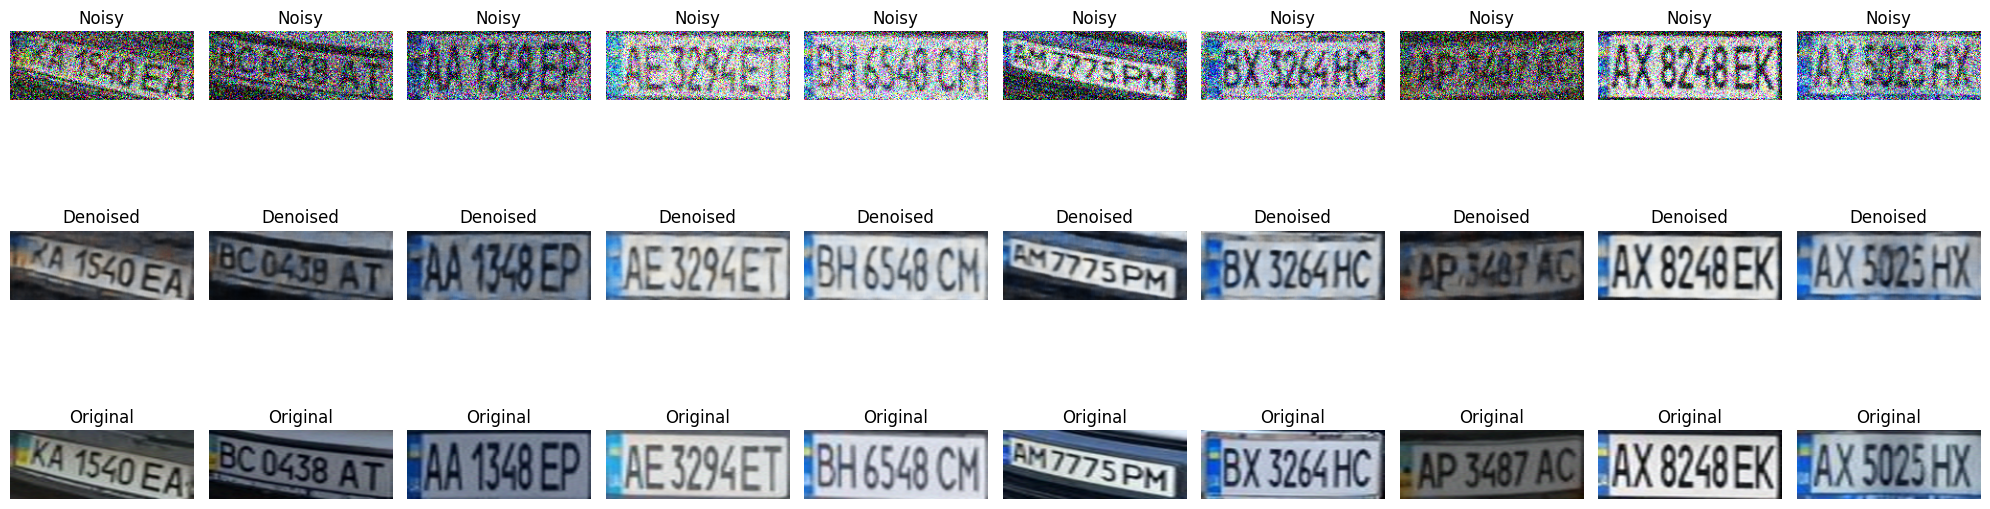

In [31]:

def display_predictions(noisy_images, predictions, clean_images, n=10):
    n = min(n, len(noisy_images))

    indices = np.random.choice(len(noisy_images), size=n, replace=False)
    images1 = noisy_images[indices]
    images2 = predictions[indices]
    images3 = clean_images[indices]
    plt.figure(figsize=(20, 7))
    for i in range(n):
        # Noisy input
        ax = plt.subplot(3, n, i + 1)
        ax.imshow(np.clip(images1[i], 0, 1))
        ax.set_title("Noisy")
        ax.axis("off")
        # Denoised prediction
        ax = plt.subplot(3, n, i + 1 + n)
        ax.imshow(np.clip(images2[i], 0, 1))
        ax.set_title("Denoised")
        ax.axis("off")
        # Original clean image
        ax = plt.subplot(3, n, i + 1 + 2*n)
        ax.imshow(np.clip(images3[i], 0, 1))
        ax.set_title("Original")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

TEST_IMG_PATH = '/content/drive/MyDrive/Colab Notebooks/test/images'
test_generator = load_data(TEST_IMG_PATH, BATCH_SIZE, training=False)
test_batch = next(train_generator)
noisy_images = test_batch[0]
clean_images = test_batch[1]

best_model = keras.models.load_model('best_model.keras')
predictions = best_model.predict(noisy_images)

print("Noisy images:", noisy_images.shape)
print("Predictions:", predictions.shape)
print("Clean images:", clean_images.shape)

display_predictions(noisy_images, predictions, clean_images, n=10)